In [1]:
# Visualization parameters
from pathlib import Path
PACKAGE_ROOT = next((path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (path / "interactions").is_dir()), None)
if PACKAGE_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside AIJ_fig_submit.")
OUTPUT_DIR = PACKAGE_ROOT / "Fig_03_distributions" / "outputs"
DATA_ROOT = str(PACKAGE_ROOT / "interactions" / "generalization")

# Models in the original figure order: CIFAR-10, MNIST, SST-2
MODELS = [
    {
        "label": "ResNet-20 on CIFAR-10",
        "prefix": "class-",
        "tau": 0.03,
        "target_root": DATA_ROOT + "/harsanyi_spilt_adv/split/dataset=cifar10_split_model=resnet20_epoch=200_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt_adv/split_baseline/dataset=cifar10_split_model=resnet20_epoch=200_bs=128_lr=0.01_weight-decay=0.0005_seed={seed}_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
    },
    {
        "label": "VGG-11 on CIFAR-10",
        "prefix": "class-",
        "tau": 0.03,
        "target_root": DATA_ROOT + "/harsanyi_spilt_adv/split/dataset=cifar10_split_model=vgg11_epoch=80_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt_adv/split_baseline/dataset=cifar10_split_model=vgg11_epoch=80_bs=128_lr=0.01_weight-decay=0.0005_seed={seed}_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
    },
    {
        "label": "ResNet-20 on MNIST",
        "prefix": "1_cluster",
        "tau": 0.01,
        "target_root": DATA_ROOT + "/harsanyi_spilt/split/dataset=mnist_split_model=resnet20_epoch=20_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt/split_baseline/dataset=mnist_split_model=resnet20_epoch=20_bs=128_lr=0.01_weight-decay=0.0005_seed={seed}_noise-label=False",
    },
    {
        "label": "VGG-11 on MNIST",
        "prefix": "1_cluster",
        "tau": 0.01,
        "target_root": DATA_ROOT + "/harsanyi_spilt/split/dataset=mnist_split_model=vgg11_epoch=20_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt/split_baseline/dataset=mnist_split_model=vgg11_epoch=20_bs=128_lr=0.01_weight-decay=0.0005_seed={seed}_noise-label=False",
    },
    {
        "label": "BERT-Medium on SST-2",
        "prefix": None,
        "tau": 0.01,
        "target_root": DATA_ROOT + "/harsanyi_spilt/split/dataset=SST-2_model=bert-medium_epoch=20_bs=128_lr=0.01_seed=0_noise-label=False",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt/split_baseline/dataset=SST-2_model=bert-medium_epoch=20_bs=128_lr=0.01_seed={seed}_noise-label=False",
    },
    {
        "label": "BERT-Base on SST-2",
        "prefix": None,
        "tau": 0.01,
        "target_root": DATA_ROOT + "/harsanyi_spilt/split/dataset=SST-2_model=bert-base_epoch=10_bs=64_lr=0.01_seed=0_noise-label=False",
        "baseline_template": DATA_ROOT + "/harsanyi_spilt/split_baseline/dataset=SST-2_model=bert-base_epoch=10_bs=64_lr=0.01_seed={seed}_noise-label=False",
    },
]

# Number of baseline seeds to compare: k = 1, 3, 5
K_VALUES = [1, 3, 5]
ALPHA_LIST = [0.7, 0.85, 1.0]
Y_SCALER = 2

FONT_SIZE = 8
BAR_WIDTH = 0.72

# Panel and figure layout
SUBPLOT_WIDTH = 1.5
SUBPLOT_HEIGHT = 1.0
WSPACE_INCHES = 0.12       # gap within each all/gen/non_gen group
HSPACE_INCHES = 0.24
GROUP_GAP_INCHES = 0.5    # extra gap between all/gen and gen/non-gen groups
LEFT_MARGIN = 0.15
RIGHT_MARGIN = 0.02
TOP_MARGIN = 0.02
BOTTOM_MARGIN = 0.20

N_ROWS = len(MODELS)
N_COLS = 7
# 7 panels + 4 internal gaps + 2 group gaps + margins
FIGWIDTH = LEFT_MARGIN + N_COLS * SUBPLOT_WIDTH + (N_COLS - 1 - 2) * WSPACE_INCHES + 2 * GROUP_GAP_INCHES + RIGHT_MARGIN
FIGHEIGHT = TOP_MARGIN + N_ROWS * SUBPLOT_HEIGHT + (N_ROWS - 1) * HSPACE_INCHES + BOTTOM_MARGIN
FIGSIZE = (FIGWIDTH, FIGHEIGHT)


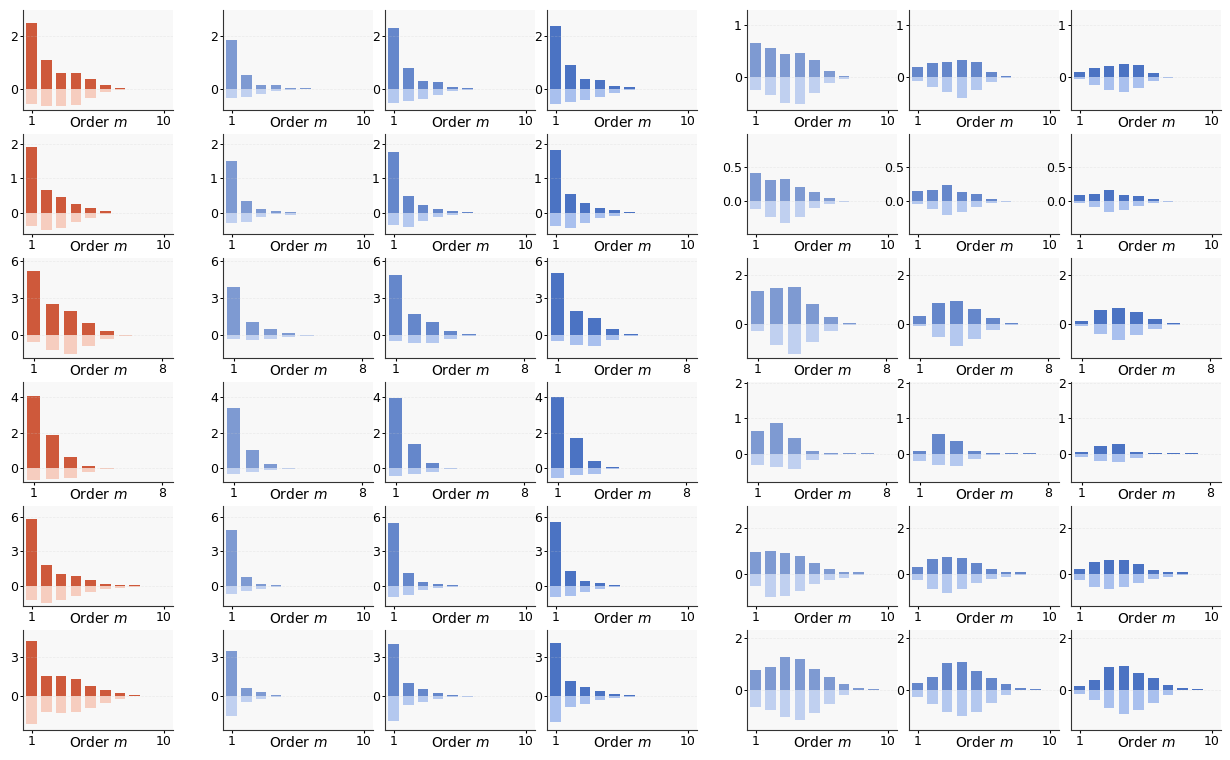

In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(PACKAGE_ROOT / "shared"))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

from tool import apply_style, COLORS, compute_generalization_orders, plot_signed_bars

apply_style(FONT_SIZE)

# Colors that match the original source notebook (main_genral_more_baseline.ipynb)
ORIG_COLORS = {
    "all_pos": "#CE593B",
    "all_neg": "#F6CDBF",
    "gen_pos": "#4B73C3",
    "gen_neg": "#A9C0EE",
}

# Local style overrides to match the original reference figure
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#333333",
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "ytick.major.width": 0.7,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "grid.color": "#CCCCCC",
    "figure.facecolor": "white",
    "axes.facecolor": "#F8F8F8",
})

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=FIGSIZE)

# Compute exact column left positions (in inches), with larger gaps between groups
col_lefts = []
x = LEFT_MARGIN
for c in range(N_COLS):
    col_lefts.append(x)
    gap = GROUP_GAP_INCHES if c in (0, 3) else WSPACE_INCHES
    x += SUBPLOT_WIDTH + gap

# Compute exact row bottom positions (in inches), from top to bottom
row_bottoms = []
y = FIGHEIGHT - TOP_MARGIN - SUBPLOT_HEIGHT
for r in range(N_ROWS):
    row_bottoms.append(y)
    y -= (SUBPLOT_HEIGHT + HSPACE_INCHES)

# Create axes manually so that group gaps can be controlled precisely
axes = [[None] * N_COLS for _ in range(N_ROWS)]
for r in range(N_ROWS):
    for c in range(N_COLS):
        left = col_lefts[c] / FIGWIDTH
        bottom = row_bottoms[r] / FIGHEIGHT
        width = SUBPLOT_WIDTH / FIGWIDTH
        height = SUBPLOT_HEIGHT / FIGHEIGHT
        axes[r][c] = fig.add_axes([left, bottom, width, height])

for r, config in enumerate(MODELS):
    # Compute distributions for each number of baseline seeds k
    dists_by_k = {}
    for k in K_VALUES:
        baseline_seeds = list(range(k))
        dists = compute_generalization_orders(
            target_root=config["target_root"],
            baseline_template=config["baseline_template"],
            baseline_seeds=baseline_seeds,
            prefix=config["prefix"],
            tau=config["tau"],
        )
        dists_by_k[k] = dists

    n_dim = len(dists_by_k[K_VALUES[0]]["all_pos"])

    # Shared y-limits across the 7 panels in this row
    all_pos_vals = []
    all_neg_vals = []
    for d in dists_by_k.values():
        all_pos_vals.extend([d["all_pos"].max(), d["gen_pos"].max(), d["non_gen_pos"].max()])
        all_neg_vals.extend([d["all_neg"].min(), d["gen_neg"].min(), d["non_gen_neg"].min()])
    y_pos_max = max(all_pos_vals) * 1.2
    y_neg_max = min(all_neg_vals) * 1.2

    def finalize_axis(ax, is_non_gen=False):
        ax.set_xticks([1, n_dim] if n_dim > 4 else np.arange(1, n_dim + 1))
        ax.tick_params(pad=1)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=3))
        # Remove the y=0 baseline drawn by plot_signed_bars
        for line in list(ax.lines):
            if np.allclose(line.get_ydata(), 0):
                line.remove()
        if is_non_gen:
            ax.set_ylim(
                (0.8 * y_neg_max - 0.2 * y_pos_max) / Y_SCALER,
                (-0.2 * y_neg_max + 0.8 * y_pos_max) / Y_SCALER,
            )
        else:
            ax.set_ylim(y_neg_max, y_pos_max)

    # Column 0: all interactions
    ax = axes[r][0]
    d = dists_by_k[K_VALUES[0]]
    plot_signed_bars(ax, d["all_pos"], d["all_neg"], ORIG_COLORS["all_pos"], ORIG_COLORS["all_neg"], width=BAR_WIDTH)
    finalize_axis(ax)
    ax.set_xlabel("Order $m$", fontsize=10)
    ax.xaxis.set_label_coords(0.5, -0.05)

    # Columns 1-3: generalizable interactions for k = 1, 3, 5
    for c, k in enumerate(K_VALUES, start=1):
        ax = axes[r][c]
        d = dists_by_k[k]
        plot_signed_bars(ax, d["gen_pos"], d["gen_neg"], ORIG_COLORS["gen_pos"], ORIG_COLORS["gen_neg"], width=BAR_WIDTH)
        alpha = ALPHA_LIST[c - 1]
        for patch in ax.patches:
            patch.set_alpha(alpha)
        finalize_axis(ax)
        ax.set_xlabel("Order $m$", fontsize=10)
        ax.xaxis.set_label_coords(0.5, -0.05)

    # Columns 4-6: non-generalizable interactions for k = 1, 3, 5
    # (use the same blue palette as generalizable panels, matching the original figure)
    for c, k in enumerate(K_VALUES, start=4):
        ax = axes[r][c]
        d = dists_by_k[k]
        plot_signed_bars(ax, d["non_gen_pos"], d["non_gen_neg"], ORIG_COLORS["gen_pos"], ORIG_COLORS["gen_neg"], width=BAR_WIDTH)
        alpha = ALPHA_LIST[c - 4]
        for patch in ax.patches:
            patch.set_alpha(alpha)
        finalize_axis(ax, is_non_gen=True)
        ax.set_xlabel("Order $m$", fontsize=10)
        ax.xaxis.set_label_coords(0.5, -0.05)

fig.savefig(OUTPUT_DIR / "main_no_text.pdf", bbox_inches=None, pad_inches=0.0)
fig.savefig(OUTPUT_DIR / "main_no_text.png", bbox_inches=None, pad_inches=0.0, dpi=300)
plt.show()
